# Asian Options

Asian options are **path-dependent** derivatives whose payoff depends on the average price of the underlying over a specified observation period, rather than the spot price at a single expiry date.

By basing the payoff on an average, these contracts reduce sensitivity to short-term price fluctuations and extreme moves at maturity. This typically lowers payoff volatility relative to standard European options and makes Asian options attractive for hedging exposures that arise gradually over time — particularly in commodity, FX, and equity-linked markets.

**Roadmap**

1. Notebook setup (imports, parameters)
2. What makes Asian options path-dependent?
3. Arithmetic vs geometric averaging
4. Analytical closed-form solutions (European)
5. Monte Carlo pricing via stochastic simulation
6. Binomial tree pricing — MC on the tree and Hull representative averages
7. American exercise for Asian options
8. Forward-starting Asians (`averaging_start > pricing_date`)
9. Explicit fixing dates
10. Discrete dividends
11. Seasoned (in-progress) Asians
12. Summary

## 1) Notebook Setup

We use the `derivatives_pricing` package for all pricing.  Key objects:

| Class / Enum | Purpose |
|---|---|
| `DiscountCurve.flat(...)` | Flat risk-free rate curve |
| `MarketData` | Bundles pricing date + discount curve |
| `UnderlyingData` | Spot, vol, market data, dividends |
| `AsianSpec` | Asian contract terms (averaging, strike, maturity, exercise) |
| `OptionValuation` | Dispatcher — routes to the appropriate engine |
| `MonteCarloParams` | Paths, seed, LSM degree, ridge regularisation |
| `BinomialParams` | Tree steps, MC paths or Hull average buckets |
| `PricingMethod` | `BSM` (analytical), `MONTE_CARLO`, `BINOMIAL` |
| `AsianAveraging` | `ARITHMETIC` or `GEOMETRIC` |
| `GBMProcess` / `SimulationConfig` | GBM path simulator + grid configuration |

In [1]:
from dataclasses import replace as dc_replace
import datetime as dt
import numpy as np
import matplotlib.pyplot as plt

import derivatives_pricing as dp

from derivatives_pricing.utils import pv_discrete_dividends

In [2]:
# ── Market / contract parameters ──────────────────────────────────────
pricing_date = dt.datetime(2025, 1, 1)
maturity = dt.datetime(2026, 1, 1)

S0 = 100.0  # spot
K = 100.0  # strike (ATM)
sigma = 0.20  # volatility
r = 0.05  # risk-free rate
q = 0.02  # continuous dividend yield
T = 1.0  # year fraction (for display)

# Build flat curves
curve_r = dp.DiscountCurve.flat(r)
curve_q = dp.DiscountCurve.flat(q)

market_data = dp.MarketData(pricing_date, curve_r, currency="USD")

underlying = dp.UnderlyingData(
    initial_value=S0,
    volatility=sigma,
    market_data=market_data,
    dividend_curve=curve_q,
)

NUM_STEPS = 60  # for pricing engines
ASIAN_OBSERVATIONS = 61  # number of Asian observation prices (including t=0)
ASIAN_TREE_AVERAGES = 2 * NUM_STEPS  # number of averages for Hull's tree approximation (see below)
# We set NUM_STEPS to 60 so the number of observation prices is 61 (matching ASIAN_OBSERVATIONS).
# However they don't need to match. The pricing engines can handle different discretization steps
# compared to number of fixing dates

print(f"Spot: {S0},  Strike: {K},  σ: {sigma},  r: {r},  q: {q},  T: {T}")
print(f"num_steps: {NUM_STEPS},  num_observations: {ASIAN_OBSERVATIONS}")

Spot: 100.0,  Strike: 100.0,  σ: 0.2,  r: 0.05,  q: 0.02,  T: 1.0
num_steps: 60,  num_observations: 61


## 2) What Makes Asian Options Path-Dependent?

A **vanilla** European option's payoff depends only on the terminal spot price $S_T$:

$$\text{Call payoff} = \max(S_T - K,\; 0)$$

An **Asian** option replaces $S_T$ with an *average* of spot prices observed at discrete dates
$t_0, t_1, \dots, t_N$ over an averaging window $[t_s, T]$:

$$\bar{S} = \frac{1}{M}\sum_{i=0}^{N} S(t_i) \qquad \text{(arithmetic)}$$

$$\text{Asian call payoff} = \max(\bar{S} - K,\; 0)$$

where $M = N + 1$ is the total number of observations and $t_i = t_s + i \cdot \Delta$ with
$\Delta = (T - t_s)/N$.

Because the payoff depends on the *entire path* of $S$ (not just the endpoint), Asian options
are **path-dependent**.  This has several important consequences:

- **No simple closed-form** for arithmetic averages (the sum of lognormals is not lognormal)
- **Lower price** than the corresponding vanilla option (averaging reduces effective volatility)
- **Resistant to short-term price spikes**: the average smooths out extreme moves near a single fixing date
- The **state space** grows: at any point in time you need both $S_t$ *and* the running average $\bar{S}_t$ to value the option

### How the pricing engines in `derivatives_pricing` handle fixing dates

For an Asian option, the user specifies observation dates in one of two ways:

1. **`num_observations`** — equally-spaced dates are implied from `averaging_start` (or `pricing_date`) to `maturity`.
2. **`fixing_dates`** — an explicit list/tuple of calendar dates.

The table below outlines how the fixing dates are processed by each engine:

| Engine | How fixing dates are used |
|---|---|
| **Monte Carlo** | The MC time grid is built from `SimulationConfig` as usual. Fixing dates are inserted as additional nodes (if not already present). The average is computed using **only** the spot values at fixing-date nodes — intermediate grid points are ignored. |
| **Binomial (Hull representative averages)** | A CRR tree is built with `num_steps` time layers as usual. For each fixing date, the algorithm selects the **nearest tree layer**. The running average is updated only at these selected layers; all other layers perform standard backward induction without updating the average state. |
| **Binomial (MC on tree)** | Same layer-snapping as Hull. Random paths through the tree record spot values only at the snapped fixing layers. |
| **Analytical (BSM)** | Converts `fixing_dates` to year fractions and passes them directly to the Turnbull-Wakeman / Kemna-Vorst moment formulas. Also accepts `num_observations` for equally spaced grids. |

### Average-price vs average-strike

This notebook focuses on **average-price** Asians: $\max(\bar{S} - K, 0)$.  The alternative is
the **average-strike** Asian: $\max(S_T - \bar{S}, 0)$, where the average replaces the strike.
`derivatives_pricing` currently supports average-price Asians.

## 3) Arithmetic vs Geometric Averaging

There are two standard averaging conventions:

### Arithmetic average

$$\bar{S}_{\text{arith}} = \frac{1}{M}\sum_{i=0}^{N} S(t_i)$$

This is by far the most common in practice (e.g. commodity settlements, structured products).

### Geometric average

$$\bar{S}_{\text{geom}} = \left(\prod_{i=0}^{N} S(t_i)\right)^{1/M} = \exp\!\left(\frac{1}{M}\sum_{i=0}^{N}\ln S(t_i)\right)$$

The geometric average is always **less than or equal to** the arithmetic average (AM-GM inequality).
Its key advantage is analytical tractability: under GBM, the geometric average of lognormal prices
is itself lognormal, yielding an **exact** closed-form price.

### Why both matter

| Property | Arithmetic | Geometric |
|---|---|---|
| Market convention | ✅ Most traded | ❌ Rare in practice |
| Closed-form price | ❌ Approximation only | ✅ Exact (Kemna-Vorst) |
| Control variate | Geometric serves as CV for arithmetic MC | — |

For **calls** with the same strike, the geometric price also provides a **lower bound** for
the arithmetic price, which is useful as a sanity check.  For **puts**, the inequality reverses.

## 4) Analytical Closed-Form Solutions (European)

`derivatives_pricing` implements two analytical approaches via `PricingMethod.ANALYTICAL`:

### 4a) Geometric average — Kemna & Vorst (1990)

Under GBM the geometric average $G = (\prod S(t_i))^{1/M}$ is lognormal with moments:

$$E[\ln G] = \ln S_0 + (r - q - \tfrac{1}{2}\sigma^2)\,\bar{t}$$

$$\text{Var}[\ln G] = \sigma^2\!\left(t_s + \frac{\Delta\,N(2N+1)}{6M}\right)$$

where $\bar{t} = t_s + N\Delta/2$ is the mean observation time and $M = N+1$.

The price is then a standard **Black-Scholes** formula applied to $G$:

$$C_{\text{geom}} = e^{-rT}\!\left[F_G\,\Phi(d_1) - K\,\Phi(d_2)\right]$$

where $F_G = \exp(E[\ln G] + \tfrac{1}{2}\text{Var}[\ln G])$ is the forward of the geometric average.

### 4b) Arithmetic average — Turnbull & Wakeman (1991)

The arithmetic average $\bar{S}$ is **not** lognormal, but its first two moments are known exactly:

$$M_1 = E[\bar{S}] = \frac{1}{M}\sum_i F_i, \qquad
  M_2 = E[\bar{S}^2] = \frac{1}{M^2}\sum_i\sum_j F_i F_j\, e^{\sigma^2 \min(t_i, t_j)}$$

where $F_i = S_0 e^{(r-q)t_i}$.  A lognormal distribution is fitted to these moments and
**Black's model** is applied.  This is Hull's recommended approach (Section 26.13).

In [3]:
# ── Analytical prices ─────────────────────────────────────────────────

spec_geo_call = dp.AsianSpec(
    averaging=dp.AsianAveraging.GEOMETRIC,
    option_type=dp.OptionType.CALL,
    exercise_type=dp.ExerciseType.EUROPEAN,
    strike=K,
    maturity=maturity,
    num_observations=ASIAN_OBSERVATIONS,
    currency="USD",
)

spec_arith_call = dc_replace(spec_geo_call, averaging=dp.AsianAveraging.ARITHMETIC)

spec_arith_put = dc_replace(spec_arith_call, option_type=dp.OptionType.PUT)

# dp.PricingMethod.ANALYTICAL dispatches to analytical formulas for dp.AsianSpec
geo_call_pv = dp.OptionValuation(
    underlying, spec_geo_call, dp.PricingMethod.ANALYTICAL
).present_value()
arith_call_pv = dp.OptionValuation(
    underlying, spec_arith_call, dp.PricingMethod.ANALYTICAL
).present_value()
arith_put_pv = dp.OptionValuation(
    underlying, spec_arith_put, dp.PricingMethod.ANALYTICAL
).present_value()

print("── Analytical (European) Asian Prices ──")
print(f"  Geometric call (Kemna-Vorst):          {geo_call_pv:.6f}")
print(f"  Arithmetic call (Turnbull-Wakeman):    {arith_call_pv:.6f}")
print(f"  Arithmetic put  (Turnbull-Wakeman):    {arith_put_pv:.6f}")
print()
print(f"  Arith call > Geom call? {arith_call_pv > geo_call_pv}  (AM-GM inequality)")

── Analytical (European) Asian Prices ──
  Geometric call (Kemna-Vorst):          4.964820
  Arithmetic call (Turnbull-Wakeman):    5.177309
  Arithmetic put  (Turnbull-Wakeman):    3.735968

  Arith call > Geom call? True  (AM-GM inequality)


### Geometric ≤ Arithmetic: an intuitive check

By the AM-GM inequality, $\bar{S}_{\text{geom}} \le \bar{S}_{\text{arith}}$ for any realisation.
Since the call payoff $\max(\bar{S} - K, 0)$ is increasing in $\bar{S}$, the geometric call
price is always **less than or equal to** the arithmetic call price (for the same strike).

For puts, the payoff $\max(K - \bar{S}, 0)$ is decreasing in $\bar{S}$, so the inequality
reverses: the geometric put price is **greater than or equal to** the arithmetic put price.

This makes the geometric call a natural **lower bound** and the geometric put a natural
**upper bound** for their arithmetic counterparts.  In Monte Carlo, the geometric payoff is
also a useful **control variate** because it is highly correlated with the arithmetic payoff
and has a known closed-form price.

## 5) Monte Carlo Pricing via Stochastic Simulation

The idea is as follows:

1. Simulate $I$ paths of $S$ on a grid $t_0, t_1, \dots, t_N$
2. For each path $i$, compute the average $\bar{S}^{(i)}$ (using the values on fixing dates)
3. Compute the payoff: $V^{(i)} = \max(\bar{S}^{(i)} - K, 0)$
4. Discount and average: $\hat{C} = e^{-rT} \cdot \frac{1}{I}\sum_i V^{(i)}$

Below we show an example implementation.

In [4]:
# ── MC setup ──────────────────────────────────────────────────────────
MC_PATHS = 200_000
MC_SEED = 42

sim_config = dp.SimulationConfig(
    paths=MC_PATHS,
    end_date=maturity,
    num_steps=NUM_STEPS,
)

gbm = dp.GBMProcess(
    market_data=market_data,
    process_params=dp.GBMParams(initial_value=S0, volatility=sigma, dividend_curve=curve_q),
    sim_config=sim_config,
)

mc_params = dp.MonteCarloParams(random_seed=MC_SEED)
# ── Monte Carlo (GBM) ──────────────────────────────────────────────────
spec_mc_arith_call = dp.AsianSpec(
    averaging=dp.AsianAveraging.ARITHMETIC,
    option_type=dp.OptionType.CALL,
    exercise_type=dp.ExerciseType.EUROPEAN,
    strike=K,
    maturity=maturity,
    num_observations=ASIAN_OBSERVATIONS,
    currency="USD",
)

spec_mc_geo_call = dc_replace(spec_mc_arith_call, averaging=dp.AsianAveraging.GEOMETRIC)

mc_arith = dp.OptionValuation(gbm, spec_mc_arith_call, dp.PricingMethod.MONTE_CARLO, mc_params)
mc_geo = dp.OptionValuation(gbm, spec_mc_geo_call, dp.PricingMethod.MONTE_CARLO, mc_params)

mc_arith_pv = mc_arith.present_value()
mc_geo_pv = mc_geo.present_value()

# Use neutral "difference" wording: Turnbull-Wakeman is a benchmark approximation
# for arithmetic Asians (not an exact ground truth).
arith_diff = mc_arith_pv - arith_call_pv
arith_pct_diff = 100.0 * arith_diff / arith_call_pv if arith_call_pv != 0 else float("nan")
geo_diff = mc_geo_pv - geo_call_pv
geo_pct_diff = 100.0 * geo_diff / geo_call_pv if geo_call_pv != 0 else float("nan")

print("── Monte Carlo Asian Prices ──")
print(f"  Arithmetic call (MC):  {mc_arith_pv:.6f}   (analytical: {arith_call_pv:.6f})")
print(f"  Geometric  call (MC):  {mc_geo_pv:.6f}   (analytical: {geo_call_pv:.6f})")
print()
print(f"  Arith MC diff:  {arith_diff:+.6f}  ({arith_pct_diff:+.3f}%)")
print(f"  Geom  MC diff:  {geo_diff:+.6f}  ({geo_pct_diff:+.3f}%)")

── Monte Carlo Asian Prices ──
  Arithmetic call (MC):  5.184151   (analytical: 5.177309)
  Geometric  call (MC):  4.987037   (analytical: 4.964820)

  Arith MC diff:  +0.006842  (+0.132%)
  Geom  MC diff:  +0.022217  (+0.447%)


### Path visualisation

Let's draw a few simulated GBM paths and shade the averaging window.  The Asian payoff
depends on the mean value of each path across the entire shaded region, not just the endpoint.

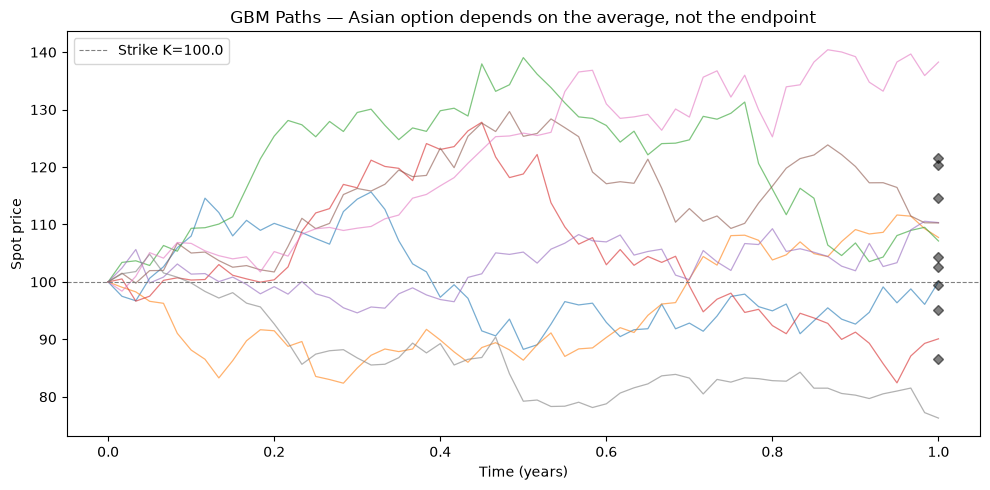

In [5]:
# ── Spaghetti plot of GBM paths ──────────────────────────────────────
n_show = 8

sim_viz = dp.SimulationConfig(
    paths=n_show,
    end_date=maturity,
    num_steps=NUM_STEPS,
    antithetic=False,
    moment_matching=False,
)
gbm_viz = dp.GBMProcess(
    market_data=market_data,
    process_params=dp.GBMParams(initial_value=S0, volatility=sigma, dividend_curve=curve_q),
    sim_config=sim_viz,
)
paths_viz = gbm_viz.simulate(random_seed=123)
tg = gbm_viz.time_grid

# Convert time grid to year fractions for x-axis
t_yf = np.array([dp.calculate_year_fraction(pricing_date, d) for d in tg])

fig, ax = plt.subplots(figsize=(10, 5))
for i in range(n_show):
    ax.plot(t_yf, paths_viz[:, i], alpha=0.6, linewidth=0.9)

ax.axhline(K, color="grey", linestyle="--", linewidth=0.8, label=f"Strike K={K}")

# Mark the arithmetic average for each path
for i in range(n_show):
    avg_i = np.mean(paths_viz[:, i])
    ax.plot(T, avg_i, "D", markersize=5, color="black", alpha=0.5)

ax.set_xlabel("Time (years)")
ax.set_ylabel("Spot price")
ax.set_title("GBM Paths — Asian option depends on the average, not the endpoint")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 6) Binomial Tree Pricing

Binomial trees are a natural framework for vanilla options, but Asian options pose a challenge:
the option's state at each node depends on the *path* taken to reach it, not just the node's
spot price.  A node at $(i, t)$ in a recombining CRR tree can be reached via many different
orderings of up/down moves, each producing a **different running average**.

`derivatives_pricing` offers two tree-based approaches:

### 6a) Monte Carlo on the tree

Sample random paths through the CRR binomial tree.  At every node, we draw a uniform
random number $u \in (0, 1]$: if $u \le p$ (the risk-neutral up probability) we take the
up move; otherwise we take the down move.  The spot values along each random path are
recorded, their average is computed, and the resulting payoff is discounted back.
Repeating for `mc_paths` independent draws gives a Monte Carlo estimate of the Asian price.

This is specified via `BinomialParams(mc_paths=...)`.

Pros: simple, handles any averaging type, scales well with steps.
Cons: MC noise

### 6b) Hull's representative averages

John Hull's method (Chapter 26) augments each node with $k$ representative average values
linearly spaced between the node's attainable minimum and maximum averages.
Backward induction then interpolates continuation values from the child nodes' average grids.

Reference: Hull, *Options, Futures, and Other Derivatives* (Ch 26)

This method is specified via `BinomialParams(asian_tree_averages=k)`.

Pros: deterministic (no MC noise), works for European and **American** exercise.
Cons: memory is $O(k \cdot N^2)$; accuracy depends on $k$ and $N$.

**Important**: when increasing `num_steps` you should increase `asian_tree_averages`
proportionally (a ratio of roughly $k \approx 2N$ is a usually a good choice).
If $k$ is too small relative to $N$ the representative averages become too coarse to
capture the option value, and the price can blow up or oscillate.

**Key insight**: the min/max running average at node $(i, t)$ corresponds to the path where all
down moves come first (min) or all up moves come first (max).  This defines the feasible
average range at every node.

For **geometric** averaging the state variable is stored in log space:
$\ln\bar{S}_{\text{geom}} = \frac{1}{t+1}\sum_{j=0}^{t} \ln S_j$.

**Fixing-date handling**: the CRR tree is built with `num_steps` time layers as usual.
Each fixing date (whether implied by `num_observations` or given as `fixing_dates`) is
snapped to the **nearest** tree layer. The running average is
updated only at these selected "fixing layers"; all other layers perform standard
backward induction without modifying the average state.

In [6]:
# ── Binomial MC on CRR tree ────────────────────────────────────────────
binom_mc_params = dp.BinomialParams(
    num_steps=NUM_STEPS,
    mc_paths=MC_PATHS,
    random_seed=MC_SEED,
)

spec_binom_arith_call = dp.AsianSpec(
    averaging=dp.AsianAveraging.ARITHMETIC,
    option_type=dp.OptionType.CALL,
    exercise_type=dp.ExerciseType.EUROPEAN,
    strike=K,
    maturity=maturity,
    num_observations=ASIAN_OBSERVATIONS,
    currency="USD",
)

binom_mc_arith = dp.OptionValuation(
    underlying, spec_binom_arith_call, dp.PricingMethod.BINOMIAL, binom_mc_params
)
binom_mc_pv = binom_mc_arith.present_value()

diff = binom_mc_pv - arith_call_pv
pct_diff = 100.0 * diff / arith_call_pv if arith_call_pv != 0 else float("nan")

print("── Binomial MC on Tree ──")
print(f"  Arithmetic call:  {binom_mc_pv:.6f}   (analytical: {arith_call_pv:.6f})")
print(f"  Diff:  {diff:+.6f}  ({pct_diff:+.3f}%)")

── Binomial MC on Tree ──
  Arithmetic call:  5.181332   (analytical: 5.177309)
  Diff:  +0.004023  (+0.078%)


In [7]:
# ── Hull representative averages ──────────────────────────────────────
hull_params = dp.BinomialParams(
    num_steps=NUM_STEPS,
    asian_tree_averages=ASIAN_TREE_AVERAGES,  # ~2x num_steps is a good rule of thumb
)

# European geometric (exact analytical benchmark available)
spec_hull_geo = dp.AsianSpec(
    averaging=dp.AsianAveraging.GEOMETRIC,
    option_type=dp.OptionType.CALL,
    exercise_type=dp.ExerciseType.EUROPEAN,
    strike=K,
    maturity=maturity,
    num_observations=ASIAN_OBSERVATIONS,
    currency="USD",
)

# European arithmetic
spec_hull_arith = dc_replace(spec_hull_geo, averaging=dp.AsianAveraging.ARITHMETIC)

hull_geo_pv = dp.OptionValuation(
    underlying, spec_hull_geo, dp.PricingMethod.BINOMIAL, hull_params
).present_value()
hull_arith_pv = dp.OptionValuation(
    underlying, spec_hull_arith, dp.PricingMethod.BINOMIAL, hull_params
).present_value()

geo_diff = hull_geo_pv - geo_call_pv
geo_pct_diff = 100.0 * geo_diff / geo_call_pv if geo_call_pv != 0 else float("nan")
arith_diff = hull_arith_pv - arith_call_pv
arith_pct_diff = 100.0 * arith_diff / arith_call_pv if arith_call_pv != 0 else float("nan")

print("── Hull Representative Averages (European) ──")
print(f"  Geometric call:   {hull_geo_pv:.6f}   (analytical: {geo_call_pv:.6f})")
print(f"  Arithmetic call:  {hull_arith_pv:.6f}   (analytical: {arith_call_pv:.6f})")
print()
print(f"  Geom  diff:  {geo_diff:+.6f}  ({geo_pct_diff:+.3f}%)")
print(f"  Arith diff:  {arith_diff:+.6f}  ({arith_pct_diff:+.3f}%)")

── Hull Representative Averages (European) ──
  Geometric call:   4.991741   (analytical: 4.964820)
  Arithmetic call:  5.186649   (analytical: 5.177309)

  Geom  diff:  +0.026921  (+0.542%)
  Arith diff:  +0.009339  (+0.180%)


## 7) American Exercise for Asian Options

American-style Asian options allow the holder to exercise at any observation date, receiving
$\max(\bar{S}_t - K, 0)$ where $\bar{S}_t$ is the running average up to time $t$.

The exercise decision at time $t$ requires comparing:
- **Intrinsic value**: $\max(\bar{S}_t - K, 0)$ (exercise now)
- **Continuation value**: $E_t[e^{-r\Delta t} \cdot V_{t+1}]$ (hold and decide later)

The state variable is **two-dimensional**: $(S_t, \bar{S}_t)$.  The running average $\bar{S}_t$
is a sufficient statistic for the path history relevant to the payoff, so the pair $(S_t, \bar{S}_t)$
is Markov.

### 7a) Longstaff-Schwartz with running average

`derivatives_pricing` extends the standard Longstaff-Schwartz (2001) algorithm to the
two-dimensional state $(S_t, \bar{S}_t)$.  Rather than regressing on raw power monomials, 
continuation values are projected onto an **additive Laguerre
polynomial basis** in three features:

| Feature | Interpretation |
|---|---|
| $\bar{S}_t / K$ | **Average moneyness** — primary driver of intrinsic value |
| $S_t / K$ | **Spot moneyness** — governs future path evolution |
| $S_t / \bar{S}_t$ | **Interaction** — captures how far spot has moved relative to the average |

The design matrix is $[L_0(\bar{S}/K), \dots, L_d(\bar{S}/K),\; L_0(S/K), \dots, L_d(S/K),\; S/\bar{S}]$
giving $2(d+1)+1$ columns — more compact and well-conditioned than full cross-monomials.
Laguerre polynomials are orthogonal on $[0, \infty)$ with weight $e^{-x}$, making them
well-suited to moneyness ratios which are always positive.

Ridge regularisation further stabilises the regression.  At each backward step, the holder
exercises when the intrinsic payoff exceeds the estimated continuation value:

$$V_t = \max\!\bigl(\text{intrinsic}_t,\; e^{-r\Delta t}\,V_{t+1}\bigr)$$

### 7b) Hull tree averages with early exercise

The Hull representative-average method naturally supports American exercise.  At each node,
backward induction compares the **interpolated continuation value** (discounted expected value
of holding) with the **intrinsic payoff** at each representative average level
$\bar{S}_t^{(k)}$ (the $k$-th average bucket at time $t$), where $\bar{S}_t$ denotes
the running average — the arithmetic (or geometric) mean of all
spot observations up to time $t$:

$$V(\bar{S}_t^{(k)}, i, t) = \max\!\bigl(\text{intrinsic}(\bar{S}_t^{(k)}),\; \text{continuation}(\bar{S}_t^{(k)})\bigr)$$

This is the tree analogue of comparing intrinsic vs discounted expected continuation —
exactly the same decision as in the vanilla American binomial tree, but now applied
per-average-bucket.

In [8]:
# ── American Asian options (MC LSM vs Hull tree) ───────────────────────

# (1) MC Longstaff-Schwartz with Laguerre basis on (A/K, S/K, S/A)
spec_american_arith = dp.AsianSpec(
    averaging=dp.AsianAveraging.ARITHMETIC,
    option_type=dp.OptionType.CALL,
    exercise_type=dp.ExerciseType.AMERICAN,  # American put has meaningful early exercise premium
    strike=K,
    maturity=maturity,
    num_observations=ASIAN_OBSERVATIONS,
    currency="USD",
)

spec_european_arith_put = dc_replace(spec_american_arith, exercise_type=dp.ExerciseType.EUROPEAN)

mc_am = dp.OptionValuation(gbm, spec_american_arith, dp.PricingMethod.MONTE_CARLO, mc_params)
mc_am_pv = mc_am.present_value()

mc_eu_put = dp.OptionValuation(
    gbm, spec_european_arith_put, dp.PricingMethod.MONTE_CARLO, mc_params
)
mc_eu_put_pv = mc_eu_put.present_value()

# Hull tree representative averages with early exercise
hull_am_params = dp.BinomialParams(num_steps=NUM_STEPS, asian_tree_averages=ASIAN_TREE_AVERAGES)

hull_am_pv = dp.OptionValuation(
    underlying, spec_american_arith, dp.PricingMethod.BINOMIAL, hull_am_params
).present_value()

hull_eu_pv = dp.OptionValuation(
    underlying, spec_european_arith_put, dp.PricingMethod.BINOMIAL, hull_am_params
).present_value()

# Analytical European put (Turnbull-Wakeman)
eu_put_analytical = dp.OptionValuation(
    underlying,
    spec_european_arith_put,
    dp.PricingMethod.ANALYTICAL,
).present_value()

label_width = 36
value_width = 12

print("── American vs European Asian Put (Monte Carlo, Binomial) ──")
print(f"{'European put (analytical T-W):':<{label_width}} {eu_put_analytical:>{value_width}.6f}")
print(f"{'European put (MC):':<{label_width}} {mc_eu_put_pv:>{value_width}.6f}")
print(f"{'European put (Hull):':<{label_width}} {hull_eu_pv:>{value_width}.6f}")
print(f"{'American put (MC LSM):':<{label_width}} {mc_am_pv:>{value_width}.6f}")
print(f"{'American put (Binomial):':<{label_width}} {hull_am_pv:>{value_width}.6f}")
print(
    f"{'Early exercise premium (MC):':<{label_width}} {(mc_am_pv - mc_eu_put_pv):>{value_width}.6f}"
)
print(
    f"{'Early exercise premium (Binomial):':<{label_width}} {(hull_am_pv - hull_eu_pv):>{value_width}.6f}"
)

── American vs European Asian Put (Monte Carlo, Binomial) ──
European put (analytical T-W):           5.177309
European put (MC):                       5.184151
European put (Hull):                     5.186649
American put (MC LSM):                   5.739926
American put (Binomial):                 5.745880
Early exercise premium (MC):             0.555775
Early exercise premium (Binomial):       0.559232


### Note on American Asian exercise

The early exercise premium for Asian options is typically small relative to vanilla Americans.
The averaging effect means that even if the current spot moves deep in-the-money, the
running average is smoothed and may not justify early exercise.

For **puts**, the premium is non-negative (exercising to capture the current favourable
average before it decays); it is zero only when early exercise is never optimal.
For **calls** with a dividend yield $q > 0$, the premium is likewise non-negative, driven by
the same logic: forgoing the continuous yield makes waiting costly.

The two methods — MC Longstaff-Schwartz and Hull tree — should produce consistent results.
Differences arise from:
- **MC noise** (reduces with more paths)
- **Tree discretisation bias** (reduces with more `asian_tree_averages`).

## 8) Forward-Starting Asians (`averaging_start > pricing_date`)

In many structured products the averaging window begins at some future date $t_s > 0$,
not at the pricing date.  For example, a 1-year option where averaging starts at the 6-month
mark.

During $[0, t_s)$ the option behaves like a forward-start: the spot diffuses freely but no
observations accumulate.  From $t_s$ onward, observations begin and the running average is built.

### How simulation handles forward-starting Asians

The MC time grid still covers the full $[0, T]$ horizon (from `pricing_date` to `maturity`).
Fixing dates derived from the `AsianSpec` all fall within $[t_s, T]$; these are inserted
into the grid as additional nodes (if not already present).  The average is computed using
only the spot values at fixing-date nodes, so observations before $t_s$ are never included.

For the Hull binomial tree, the same layer-snapping logic applies: fixing dates are mapped
to the nearest tree layer, and only those layers update the running average.

In [9]:
# ── Forward-starting Asian (averaging starts at 6M) ────────────────────
averaging_start = dt.datetime(2025, 7, 1)  # 6 months in
T_avg = dp.calculate_year_fraction(averaging_start, maturity)
spec_fwd_arith = dp.AsianSpec(
    averaging=dp.AsianAveraging.ARITHMETIC,
    option_type=dp.OptionType.CALL,
    exercise_type=dp.ExerciseType.EUROPEAN,
    strike=K,
    maturity=maturity,
    averaging_start=averaging_start,
    num_observations=ASIAN_OBSERVATIONS,
    currency="USD",
)
spec_fwd_geo = dc_replace(spec_fwd_arith, averaging=dp.AsianAveraging.GEOMETRIC)

fwd_arith_analytical = dp.OptionValuation(
    underlying, spec_fwd_arith, dp.PricingMethod.ANALYTICAL
).present_value()

fwd_geo_analytical = dp.OptionValuation(
    underlying, spec_fwd_geo, dp.PricingMethod.ANALYTICAL
).present_value()

# MC — fixing dates are inserted into the grid automatically
sim_fwd = dp.SimulationConfig(
    paths=MC_PATHS,
    end_date=maturity,
    num_steps=NUM_STEPS,
)

gbm_fwd = dp.GBMProcess(
    market_data=market_data,
    process_params=dp.GBMParams(initial_value=S0, volatility=sigma, dividend_curve=curve_q),
    sim_config=sim_fwd,
)

mc_fwd_pv = dp.OptionValuation(
    gbm_fwd, spec_fwd_arith, dp.PricingMethod.MONTE_CARLO, mc_params
).present_value()

# Hull tree representative averages with early exercise
hull_am_params = dp.BinomialParams(num_steps=NUM_STEPS, asian_tree_averages=ASIAN_TREE_AVERAGES)

ud_fix = dp.UnderlyingData(
    initial_value=S0,
    volatility=sigma,
    market_data=market_data,
    dividend_curve=curve_q,
)

hull_fwd_pv = dp.OptionValuation(
    underlying, spec_fwd_arith, dp.PricingMethod.BINOMIAL, hull_am_params
).present_value()

mc_diff = mc_fwd_pv - fwd_arith_analytical
mc_pct_diff = 100.0 * mc_diff / fwd_arith_analytical if fwd_arith_analytical != 0 else float("nan")

hull_diff = hull_fwd_pv - fwd_arith_analytical
hull_pct_diff = (
    100.0 * hull_diff / fwd_arith_analytical if fwd_arith_analytical != 0 else float("nan")
)

print("── Forward-Starting Asian (averaging starts at 6M) ──")
print(f"  Averaging window: {averaging_start.date()} → {maturity.date()}")
print(f"  T_avg = {T_avg:.4f} years")
print()
print(f"  Geometric call (analytical):   {fwd_geo_analytical:.6f}")
print(f"  Arithmetic call (analytical):  {fwd_arith_analytical:.6f}")
print(f"  Arithmetic call (MC):          {mc_fwd_pv:.6f}")
print(f"  Arithmetic call (Binomial):     {hull_fwd_pv:.6f}")
print(f"  MC vs analytical diff:         {mc_diff:+.6f}  ({mc_pct_diff:+.3f}%)")
print(f"  Binomial vs analytical diff:   {hull_diff:+.6f}  ({hull_pct_diff:+.3f}%)")

── Forward-Starting Asian (averaging starts at 6M) ──
  Averaging window: 2025-07-01 → 2026-01-01
  T_avg = 0.5041 years

  Geometric call (analytical):   7.282263
  Arithmetic call (analytical):  7.384314
  Arithmetic call (MC):          7.399199
  Arithmetic call (Binomial):     7.388986
  MC vs analytical diff:         +0.014885  (+0.202%)
  Binomial vs analytical diff:   +0.004673  (+0.063%)


### Forward-starting vs spot-starting: price comparison

Forward-starting Asians are typically **more expensive** than spot-starting Asians (same
maturity, strike, etc.) because the averaging window is shorter, so there is less
volatility reduction from averaging.

In the limit where `averaging_start = maturity` (a single observation), the Asian
degenerates to a vanilla European.

In [10]:
# ── Forward-start vs spot-start comparison ────────────────────────────

# Spot-starting (averaging over full [0, T])
spot_start_pv = arith_call_pv

# Forward-starting (averaging over [0.5, 1.0])
fwd_start_pv = fwd_arith_analytical

# Almost-vanilla (averaging starts 1 day before maturity)
near_vanilla_spec = dp.AsianSpec(
    averaging=dp.AsianAveraging.ARITHMETIC,
    option_type=dp.OptionType.CALL,
    exercise_type=dp.ExerciseType.EUROPEAN,
    strike=K,
    maturity=maturity,
    averaging_start=dt.datetime(2025, 12, 31),
    num_observations=2,
    currency="USD",
)
near_vanilla_pv = dp.OptionValuation(
    underlying, near_vanilla_spec, dp.PricingMethod.ANALYTICAL
).present_value()

# True vanilla BSM
vanilla_spec = dp.VanillaSpec(
    option_type=dp.OptionType.CALL,
    exercise_type=dp.ExerciseType.EUROPEAN,
    strike=K,
    maturity=maturity,
    currency="USD",
)
vanilla_pv = dp.OptionValuation(
    underlying, vanilla_spec, dp.PricingMethod.ANALYTICAL
).present_value()

print("── Asian Price vs Averaging Window Length ──")
print(f"  Spot-starting  (0M → 12M avg):  {spot_start_pv:.6f}")
print(f"  Forward-start  (6M → 12M avg):  {fwd_start_pv:.6f}")
print(f"  Near-vanilla   (≈12M→12M avg):  {near_vanilla_pv:.6f}")
print(f"  Vanilla BSM European:            {vanilla_pv:.6f}")
print()
print("As the averaging window shrinks → Asian price converges to vanilla price.")

── Asian Price vs Averaging Window Length ──
  Spot-starting  (0M → 12M avg):  5.177309
  Forward-start  (6M → 12M avg):  7.384314
  Near-vanilla   (≈12M→12M avg):  9.216802
  Vanilla BSM European:            9.227006

As the averaging window shrinks → Asian price converges to vanilla price.


## 9) Explicit Fixing Dates

Real-world Asian options observe the spot on **specific calendar dates** (e.g. monthly
15th, weekly Fridays, IMM dates, end of each month) rather than at equally-spaced
points on a continuous time grid.

`AsianSpec.fixing_dates` lets you specify every observation date explicitly.
The simulation time grid will include these dates as exact nodes, but **only** the
spot values at fixing dates enter the average — any intermediate grid dates (used for
diffusion accuracy) are excluded.

Monthly fixings over 12 months:

In [11]:
# ── Monthly fixing dates: 15th of each month ─────────────────────
monthly_fixings = tuple(dt.datetime(2025, m, 15) for m in range(1, 13))

spec_monthly = dp.AsianSpec(
    averaging=dp.AsianAveraging.ARITHMETIC,
    option_type=dp.OptionType.CALL,
    exercise_type=dp.ExerciseType.EUROPEAN,
    strike=K,
    maturity=maturity,
    currency="USD",
    fixing_dates=monthly_fixings,
)

# MC pricing with explicit fixing dates
sim_fix = dp.SimulationConfig(
    paths=MC_PATHS,
    end_date=maturity,
    num_steps=NUM_STEPS,  # dense grid for diffusion accuracy
)
gbm_fix = dp.GBMProcess(
    market_data=market_data,
    process_params=dp.GBMParams(initial_value=S0, volatility=sigma, dividend_curve=curve_q),
    sim_config=sim_fix,
)

fix_mc_pv = dp.OptionValuation(
    gbm_fix, spec_monthly, dp.PricingMethod.MONTE_CARLO, mc_params
).present_value()

# ── Hull representative averages ──────────────────────────────────────
hull_params = dp.BinomialParams(
    num_steps=NUM_STEPS,
    asian_tree_averages=ASIAN_TREE_AVERAGES,
)

ud_fix = dp.UnderlyingData(
    initial_value=S0,
    volatility=sigma,
    market_data=market_data,
    dividend_curve=curve_q,
)

fix_hull_pv = dp.OptionValuation(
    ud_fix, spec_monthly, dp.PricingMethod.BINOMIAL, hull_params
).present_value()

# ── Analytical (BSM) with fixing dates ──────────────────────────────
fix_bsm_pv = dp.OptionValuation(ud_fix, spec_monthly, dp.PricingMethod.ANALYTICAL).present_value()

spec_monthly_geo = dc_replace(spec_monthly, averaging=dp.AsianAveraging.GEOMETRIC)
fix_geo_mc_pv = dp.OptionValuation(
    gbm_fix, spec_monthly_geo, dp.PricingMethod.MONTE_CARLO, mc_params
).present_value()
fix_geo_bsm_pv = dp.OptionValuation(
    ud_fix, spec_monthly_geo, dp.PricingMethod.ANALYTICAL
).present_value()

print("── Explicit Monthly Fixings vs Equally-Spaced Grid ──")
print(f"  Arithmetic call (MC, {len(monthly_fixings)} obs):        {fix_mc_pv:.6f}")
print(f"  Arithmetic call (Binomial, {len(monthly_fixings)} obs):  {fix_hull_pv:.6f}")
print(f"  Arithmetic call (BSM T-W, {len(monthly_fixings)} obs):   {fix_bsm_pv:.6f}")
print()
print(f"  Geometric call (MC, {len(monthly_fixings)} obs):         {fix_geo_mc_pv:.6f}")
print(f"  Geometric call (BSM K-V, {len(monthly_fixings)} obs):    {fix_geo_bsm_pv:.6f}")
print()

── Explicit Monthly Fixings vs Equally-Spaced Grid ──
  Arithmetic call (MC, 12 obs):        5.164187
  Arithmetic call (Binomial, 12 obs):  5.143338
  Arithmetic call (BSM T-W, 12 obs):   5.156547

  Geometric call (MC, 12 obs):         4.971786
  Geometric call (BSM K-V, 12 obs):    4.949513



Fixing dates offers flexibility. Suppose observations begin at 15 Jul 2025 (6 months forward) and run monthly until maturity:

In [12]:
# ── Forward-starting: monthly fixings from July to December ──────────
fwd_fixings = tuple(dt.datetime(2025, m, 15) for m in range(7, 13))

fwd_monthly_spec = dc_replace(spec_monthly, fixing_dates=fwd_fixings)

fwd_fix_mc_pv = dp.OptionValuation(
    gbm_fix, fwd_monthly_spec, dp.PricingMethod.MONTE_CARLO, mc_params
).present_value()

fwd_fix_hull_pv = dp.OptionValuation(
    ud_fix, fwd_monthly_spec, dp.PricingMethod.BINOMIAL, hull_params
).present_value()

fwd_fix_bsm_pv = dp.OptionValuation(
    ud_fix, fwd_monthly_spec, dp.PricingMethod.ANALYTICAL
).present_value()

# Compare against the default equally-spaced grid (same number of observations)
spec_equal = dp.AsianSpec(
    averaging=dp.AsianAveraging.ARITHMETIC,
    option_type=dp.OptionType.CALL,
    exercise_type=dp.ExerciseType.EUROPEAN,
    strike=K,
    maturity=maturity,
    currency="USD",
    num_observations=len(monthly_fixings),  # same count of observations
)

spec_equal = dc_replace(spec_equal, num_observations=len(fwd_fixings))
eq_pv = dp.OptionValuation(underlying, spec_equal, dp.PricingMethod.ANALYTICAL).present_value()

print("── Fwd Monthly Fixings ──")
print(f"  Original monthly fixings (MC, {len(monthly_fixings)} obs):       {fix_mc_pv:.6f}")
print(f"  Forward-start monthly fixings (MC, {len(fwd_fixings)} obs):      {fwd_fix_mc_pv:.6f}")
print(f"  Forward-start monthly fixings (Binomial, {len(fwd_fixings)} obs):{fwd_fix_hull_pv:>9.6f}")
print(f"  Forward-start monthly fixings (BSM, {len(fwd_fixings)} obs):     {fwd_fix_bsm_pv:.6f}")
print()
print("Fewer observations (shorter averaging window) → less averaging effect → higher price.")

── Fwd Monthly Fixings ──
  Original monthly fixings (MC, 12 obs):       5.164187
  Forward-start monthly fixings (MC, 6 obs):      7.407724
  Forward-start monthly fixings (Binomial, 6 obs): 7.379226
  Forward-start monthly fixings (BSM, 6 obs):     7.381785

Fewer observations (shorter averaging window) → less averaging effect → higher price.


### Key points

- **`fixing_dates`** gives full control over when observations occur — useful for
  matching real term sheets with irregular schedules.
- The simulation grid is **augmented** with fixing dates as exact nodes; intermediate
  steps remain for diffusion accuracy but don’t enter the average.
- Works with both **European and American** exercise, and with **arithmetic or geometric**
  averaging.
- **Analytical (BSM)** pricing also supports explicit `fixing_dates` — the Kemna-Vorst and
  Turnbull-Wakeman formulas generalise naturally to arbitrary observation times.

## 10) Discrete Dividends

Discrete dividends cause drops in the stock price at ex-dates, which directly affect the average.
How each pricing method handles them:

| Method | Discrete dividends | Notes |
|---|---|---|
| **Analytical** (BSM) | ❌ Not supported | T-W / K-V formulas assume continuous yield only |
| **Monte Carlo** | ✅ Supported | Simulates spot paths with cash-dividend jumps at ex-dates |
| **Binomial (MC on tree)** | ✅ Supported | Escrowed-dividend / prepaid-forward lattice + MC sampling |
| **Binomial (Hull avgs)** | ✅ Supported | Escrowed-dividend / prepaid-forward lattice + representative averages |

When discrete dividends are present, the analytical formula raises `UnsupportedFeatureError` — you must use MC or binomial.

### Why MC and binomial can disagree

Even with the same inputs, MC and binomial may produce different prices because they are (slightly) different **discrete-dividend models**:

- **MC (GBMProcess with discrete dividends)**: simulates the spot and applies an additive jump at each ex-date
  $$S_{t^+} = \max(S_{t^-} - D, 0).$$
- **Binomial**: builds an **escrowed-dividend / prepaid-forward** lattice by splitting the stock into a risky component and a riskless dividend component.
  A common view is to treat the risky process as the prepaid forward $S^* = S_0 - PV(\text{divs})$, then build the CRR tree on $S^*$.
  For **American** exercise, the PV of remaining dividends is added back at each node so that the exercise decision uses the correct (cum-dividend) spot.

A useful (but heuristic) adjustment is to scale volatility when using the prepaid-forward lattice, since
the risky component is smaller than $S_0$:

$$\sigma^* \approx \sigma \cdot \frac{S_0}{S_0 - PV(\text{divs})}.$$

This can move the binomial price closer to the MC result.

In [13]:
# ── Discrete dividends: MC vs binomial ─────────────────────────────────
ex_date_1 = dt.datetime(2025, 4, 1)
ex_date_2 = dt.datetime(2025, 10, 1)
divs = [(ex_date_1, 2.0), (ex_date_2, 2.0)]  # two $2 dividends

underlying_div = dp.UnderlyingData(
    initial_value=S0,
    volatility=sigma,
    market_data=market_data,
    discrete_dividends=divs,
    # No continuous dividend yield — just the two discrete payments
)

spec_div_mc = dp.AsianSpec(
    averaging=dp.AsianAveraging.ARITHMETIC,
    option_type=dp.OptionType.CALL,
    exercise_type=dp.ExerciseType.EUROPEAN,
    strike=K,
    maturity=maturity,
    num_observations=ASIAN_OBSERVATIONS,
    currency="USD",
)

# MC with discrete dividends: simulate spot and subtract dividends at ex-dates
sim_div = dp.SimulationConfig(paths=MC_PATHS, end_date=maturity, num_steps=NUM_STEPS)
gbm_div = dp.GBMProcess(
    market_data=market_data,
    process_params=dp.GBMParams(initial_value=S0, volatility=sigma, discrete_dividends=divs),
    sim_config=sim_div,
)
mc_div_pv = dp.OptionValuation(
    gbm_div, spec_div_mc, dp.PricingMethod.MONTE_CARLO, mc_params
).present_value()

# Binomial tree MC with discrete dividends: escrowed-dividend / prepaid-forward lattice
binom_div_params = dp.BinomialParams(num_steps=NUM_STEPS, mc_paths=MC_PATHS, random_seed=MC_SEED)
binom_div_pv = dp.OptionValuation(
    underlying_div, spec_div_mc, dp.PricingMethod.BINOMIAL, binom_div_params
).present_value()

# Heuristic: volatility adjustment for the prepaid-forward risky component
pv_divs = pv_discrete_dividends(
    divs,
    pricing_date,
    maturity,
    market_data.discount_curve,
)
vol_multiplier = S0 / (S0 - pv_divs)
underlying_div_vol_adj = dp.UnderlyingData(
    initial_value=S0,
    volatility=sigma * vol_multiplier,
    market_data=market_data,
    discrete_dividends=divs,
)
binom_div_pv_vol_adj = dp.OptionValuation(
    underlying_div_vol_adj, spec_div_mc, dp.PricingMethod.BINOMIAL, binom_div_params
).present_value()

print("── Discrete Dividends: European Arithmetic Asian Call ──")
print(f"  No dividends (MC):                 {mc_arith_pv:.6f}")
print(f"  With 2 × $2 divs (MC):            {mc_div_pv:.6f}")
print(f"  With 2 × $2 divs (binom):         {binom_div_pv:.6f}")
print(f"  With 2 × $2 divs (binom, σ* adj): {binom_div_pv_vol_adj:.6f}")
print()
print(f"  PV(divs) = {pv_divs:.6f}")
print(f"  σ* multiplier = {vol_multiplier:.6f}  →  σ* = {sigma * vol_multiplier:.6%}")

── Discrete Dividends: European Arithmetic Asian Call ──
  No dividends (MC):                 5.184151
  With 2 × $2 divs (MC):            4.700150
  With 2 × $2 divs (binom):         4.560189
  With 2 × $2 divs (binom, σ* adj): 4.735526

  PV(divs) = 3.902081
  σ* multiplier = 1.040605  →  σ* = 20.812105%


## 11) Seasoned Asians

A **seasoned** Asian is one where part of the averaging window has already elapsed.  We have $n_1$
past fixings with observed average $\bar{S}_{\text{obs}}$ and $n_2$ future fixings remaining.

The payoff at maturity is:

$$\max\!\left(\frac{n_1 \bar{S}_{\text{obs}} + n_2 \bar{S}_{\text{future}}}{n_1 + n_2} - K,\; 0\right)$$

### Hull's adjusted-strike reduction (European, arithmetic Asians only)

This can be rewritten as:

$$\frac{n_2}{n_1 + n_2}\;\max\!\left(\bar{S}_{\text{future}} - K^*,\; 0\right)$$

where the **adjusted strike** is:

$$K^* = \frac{n_1 + n_2}{n_2}\,K - \frac{n_1}{n_2}\,\bar{S}_{\text{obs}}$$

When $K^* > 0$: price a fresh Asian with strike $K^*$ and scale by $n_2/(n_1 + n_2)$.

When $K^* \le 0$: for a **call**, the option is certain to be exercised and the value equals a
scaled forward-style value on the remaining average.  For a **put**, $K^* \le 0$ implies the
future payoff is $0$ (since the remaining average is positive).

> **Note:** This $K^*$ decomposition is a **European-only, arithmetic-only** identity.  The
> BSM analytical engine applies it automatically.  It is not valid for geometric averaging
> (where the log-sum structure doesn't factorise this way) or for American exercise (where
> early-exercise decisions depend on the running average, not a single adjusted strike).

### Monte Carlo and Binomial engines

The **Monte Carlo** and **Binomial (Hull tree)** engines handle seasoned Asians directly
by folding the past observations into their running-average calculations — no strike
adjustment is needed.  This means they naturally support:
- Both **arithmetic and geometric** averaging
- Both **European and American** exercise (the tree/LSM early-exercise logic sees the
  correct running average at each node, including the past observed portion)

All engines accept the same API: one can set `observed_average` and `observed_count` on `AsianSpec`.

In [14]:
# ── Seasoned Asian example (BSM analytical — K* reduction) ───────────
# Suppose 20 out of 61 fixings have been observed, with average $102
n1 = 20
n2 = NUM_STEPS + 1 - n1  # 41 future fixings
S_bar_obs = 102.0

spec_seasoned = dp.AsianSpec(
    averaging=dp.AsianAveraging.ARITHMETIC,
    option_type=dp.OptionType.CALL,
    exercise_type=dp.ExerciseType.EUROPEAN,
    strike=K,
    maturity=maturity,
    num_observations=n2,  # future fixings -> n2 number of prices
    currency="USD",
    observed_average=S_bar_obs,
    observed_count=n1,
)

seasoned_pv = dp.OptionValuation(
    underlying, spec_seasoned, dp.PricingMethod.ANALYTICAL
).present_value()

K_star = (n1 + n2) / n2 * K - n1 / n2 * S_bar_obs
scale = n2 / (n1 + n2)

print("── Seasoned Asian Call (BSM analytical via K*) ──")
print(f"  n₁ = {n1} observed,  n₂ = {n2} remaining")
print(f"  Observed average S̄ = {S_bar_obs}")
print(f"  Adjusted strike K* = {K_star:.4f}")
print(f"  Scale factor = {scale:.4f}")
print(f"  Seasoned Asian PV = {seasoned_pv:.6f}")
print()
if K_star > 0:
    # Price the fresh Asian with K* for verification
    spec_fresh = dp.AsianSpec(
        averaging=dp.AsianAveraging.ARITHMETIC,
        option_type=dp.OptionType.CALL,
        exercise_type=dp.ExerciseType.EUROPEAN,
        strike=K_star,
        maturity=maturity,
        num_observations=n2,
        currency="USD",
    )
    fresh_pv = dp.OptionValuation(
        underlying, spec_fresh, dp.PricingMethod.ANALYTICAL
    ).present_value()
    print(
        f"  Verification: scale × fresh_PV(K*) = {scale:.4f} × {fresh_pv:.6f} = {scale * fresh_pv:.6f}"
    )

# ── Same seasoned spec priced by MC and Binomial (no K* needed) ──────
print()
print("── Seasoned Asian Call (MC & Binomial — direct folding) ──")

# MC
sim_seasoned = dp.SimulationConfig(paths=200_000, num_steps=n2 - 1, end_date=maturity)
gbm_seasoned = dp.GBMProcess(
    market_data=market_data,
    process_params=dp.GBMParams(initial_value=S0, volatility=sigma, dividend_curve=curve_q),
    sim_config=sim_seasoned,
)
mc_seasoned_pv = dp.OptionValuation(
    gbm_seasoned, spec_seasoned, dp.PricingMethod.MONTE_CARLO, mc_params
).present_value()
print(f"  MC  (200k paths): {mc_seasoned_pv:.6f}")

# Binomial
binom_seasoned_pv = dp.OptionValuation(
    underlying,
    spec_seasoned,
    dp.PricingMethod.BINOMIAL,
    dp.BinomialParams(num_steps=n2 - 1, asian_tree_averages=int(1.5 * n2)),
).present_value()
print(f"  Binomial (Hull):  {binom_seasoned_pv:.6f}")
print(f"  BSM (K*):         {seasoned_pv:.6f}")

── Seasoned Asian Call (BSM analytical via K*) ──
  n₁ = 20 observed,  n₂ = 41 remaining
  Observed average S̄ = 102.0
  Adjusted strike K* = 99.0244
  Scale factor = 0.6721
  Seasoned Asian PV = 3.814672

  Verification: scale × fresh_PV(K*) = 0.6721 × 5.675487 = 3.814672

── Seasoned Asian Call (MC & Binomial — direct folding) ──


  MC  (200k paths): 3.816247
  Binomial (Hull):  3.827675
  BSM (K*):         3.814672


## 12) Summary

### Key takeaways

1. **Asian options are path-dependent**: the payoff depends on the average price over
   a window, not a single terminal value.  This makes them cheaper than vanillas
   (averaging reduces effective volatility).

2. **Arithmetic vs geometric**: arithmetic is the market standard but has no exact
   closed-form.  Geometric has an exact formula (Kemna-Vorst) and serves as a control variate.

3. **Analytical pricing** (European only):
   - **Geometric**: Kemna-Vorst (1990) — exact BSM-like formula
   - **Arithmetic**: Turnbull-Wakeman (1991) — moment-matching approximation via Black's model

4. **Monte Carlo** handles all cases: European, American, arithmetic, geometric, discrete
   dividends, forward-starting.  Longstaff-Schwartz with Laguerre basis on average-moneyness
   $\bar{S}_t/K$, spot-moneyness $S_t/K$, and the interaction $S_t/\bar{S}_t$ enables American
   exercise.

5. **Binomial trees** offer two modes:
   - **MC on tree**: sample random paths through CRR lattice
   - **Hull representative averages**: deterministic, memory $O(k \cdot N^2)$, supports
     both European and American exercise

6. **Forward-starting Asians** (`averaging_start > pricing_date`): fixing dates are derived
   from the averaging window $[t_s, T]$.  MC inserts these into the full $[0, T]$ grid;
   binomial snaps them to the nearest tree layer.  No observations accumulate before $t_s$.

7. **Explicit fixing dates** (`fixing_dates`): specify exact observation dates for all pricing
   methods.  The Kemna-Vorst and Turnbull-Wakeman formulas generalise naturally to arbitrary
   observation times; MC augments the simulation grid; binomial snaps dates to tree layers.

8. **Discrete dividends** are handled by MC and binomial (not analytical).  They reduce the
   average and hence the call price.

9. **Seasoned Asians** with partial observations are handled by all three engines.  The BSM
   analytical engine uses Hull's adjusted-strike $K^*$ reduction (European arithmetic only).
   MC and Binomial fold past observations directly into running averages, naturally supporting
   both averaging types and American exercise.

### Pricing method selection guide

| Scenario | Recommended method |
|---|---|
| European geometric average | `PricingMethod.ANALYTICAL` (exact Kemna-Vorst) |
| European arithmetic average, quick estimate | `PricingMethod.ANALYTICAL` (Turnbull-Wakeman approximation) |
| American exercise | `PricingMethod.MONTE_CARLO` (LSM) or `BINOMIAL` (Hull tree) |
| Discrete dividends | `PricingMethod.MONTE_CARLO` or `BINOMIAL` |
| Explicit fixing dates | Any method — `PricingMethod.ANALYTICAL`, `MONTE_CARLO`, or `BINOMIAL` with `fixing_dates` on spec |
| Seasoned (in-progress) | Any method — `AsianSpec(observed_average=..., observed_count=...)` except geometric analytical|